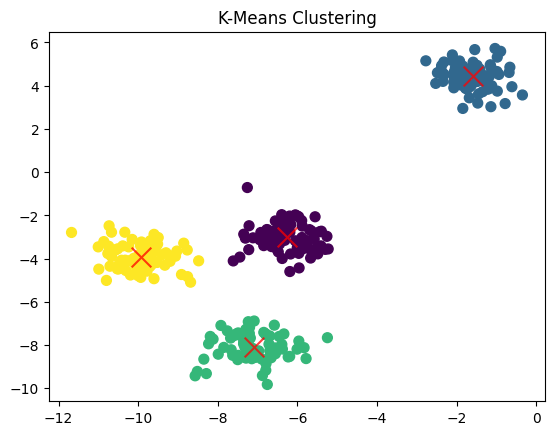

In [2]:
# unit-3 Unsupervised Learning      
# K-means Clustering
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs #make_blobs creates dataset useful for k-means
import matplotlib.pyplot as plt

# Creating sample dataset
x,y=make_blobs(n_samples=300, centers=4, cluster_std=0.6, random_state=1)
# n_samples=300 means 300 records are generated
# centers=4 means it creates 4 clusters
# cluster_std=0.6 means the spread of the cluster (small number means tighter cluster)
# random_sate=0 menas fixes the random seed so results are reproducible

# Apply K-Means
kmeans= KMeans(n_clusters=4) #4 clusters will be formed
kmeans.fit(x) #trains the K-Means model with the data
y_kmeans=kmeans.predict(x)

# Visualise clusters 
plt.scatter(x[:,0], x[:,1], c=y_kmeans, s=50, cmap='viridis') #code for elements of the cluster
# x[:,0] is the first feature (x-axis), x[:,1] is the second feature (y-axis)
# c=y_kmeans as cluster size is 4, colors each point according to the cluster
# s=50 it is the size of the marker
# cmap='viridis' it colors each cluster with different colors

centers = kmeans.cluster_centers_ #stores the coordinate of the clusters centroid
plt.scatter(centers[:,0], centers[:,1], c='red', s=200, alpha=0.75, marker= 'x') #code for elements of the centroid
# centers[:,0] and centers[:,1] are centroid coordinates
# c='red' colors the centroid with red color
# s=200 sixe of the centroids
# alpha=0.75 makes cebtroid little bit transparent
# marker= 'x' uses X symbol as a marker

plt.title('K-Means Clustering')
plt.show()

In [2]:
#k-means ma maker ni values...
# 'o': Circle
# 's': Square
# '^': Triangle up
# 'v': Triangle down
# '<': Triangle left
# '>': Triangle right
# '8': Octagon
# 'p': Pentagon
# 'P': Plus (filled)
# '*' : Star
# 'h': Hexagon (1)...shape ma upar pointed che
# 'H': Hexagon (2)... shape ma upar horizontal line ave che ne side ma pointed che
# '+': Plus
# 'x': X
# 'X': X (filled)
# 'D': Diamond
# 'd': Thin diamond
# '.': Point
# ',': Pixel
# '|': Vertical line
# '_': Horizontal line

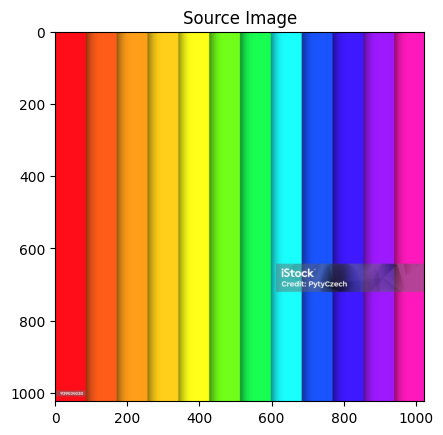

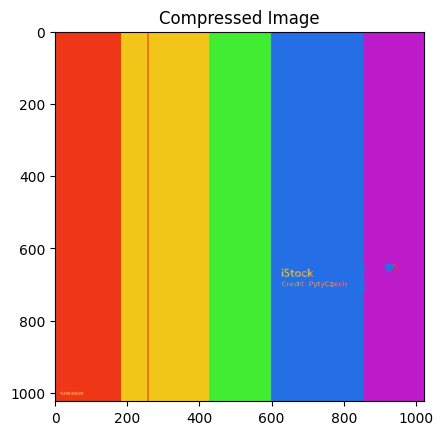

In [6]:
#Vector Quantization

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import io #pip install scikit-image

#Reading an image
image = io.imread('color.jpg')
plt.imshow(image)
plt.title('Source Image')
plt.show()

#Reshaping the image data
pixels = image.reshape(-1 , 3)
#Converts img pixels to 2d array , one pixel per row , 3 coloumns for RGB

#Appling the k-means for the color quantization
k=5
kmeans = KMeans(n_clusters = k)
kmeans.fit(pixels)
new_colors = kmeans.cluster_centers_[kmeans.labels_]
#cluster_centers_ , gives representative colors
# labels_ , tells which cluster each pixels belongs to 

#Recreating the compressed image
compressed = new_colors.reshape(image.shape).astype('uint8')
#8-bit unsigned integer is a standard datatype for image pixels

#Display
plt.imshow(compressed)
plt.title('Compressed Image')
plt.show()

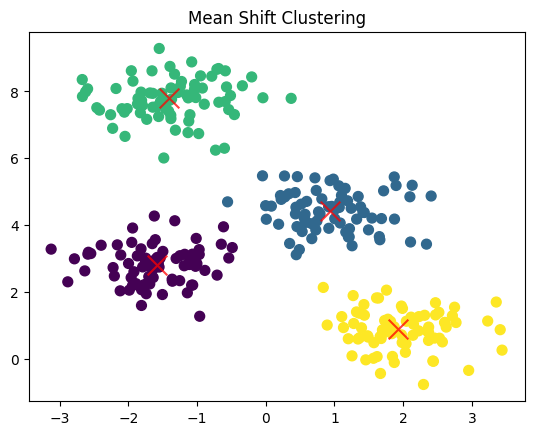

In [33]:
# Mean Shift Clustring Model
from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# Creating the data as required
x,_=make_blobs(n_samples=300, centers=4, cluster_std=0.6, random_state=0)
# n_samples=300 means 300 records are generated
# centers=4 means it creates 4 clusters
# cluster_std=0.6 means the spread of the cluster (small number means tighter cluster)
# random_sate=0 menas fixes the random seed so results are reproducible

# Estimate a suitable bandwidth automatically
bandwidth=estimate_bandwidth(x,quantile=0.2, n_samples=300) #Bandwidth means radius of the window around each point
                                                            # quantile=0.2 means the width of the window

# Creating the MeanShift object
ms=MeanShift(bandwidth=bandwidth, bin_seeding=True)#   bin_seeding=True meqan speed-up the computation by using initial bin centers

# Fitting the data to the model
ms.fit(x)
labels=ms.labels_
cluster_centers=ms.cluster_centers_

# Visualise the results
plt.scatter(x[:,0], x[:,1], c=labels, s=50, cmap='viridis') #code for elements of the cluster
# x[:,0] is the first feature (x-axis), x[:,1] is the second feature (y-axis)
# c=y_kmeans as cluster size is 4, colors each point according to the cluster
# s=50 it is the size of the marker
# cmap='viridis' it colors each cluster with different colors

plt.scatter(cluster_centers[:,0], cluster_centers[:,1], c='red', s=200, alpha=0.75, marker= 'x') #code for elements of the centroid
# centers[:,0] and centers[:,1] are centroid coordinates
# c='red' colors the centroid with red color
# s=200 sixe of the centroids
# alpha=0.75 makes cebtroid little bit transparent
# marker= 'x' uses X symbol as a marker

plt.title('Mean Shift Clustering')
plt.show()

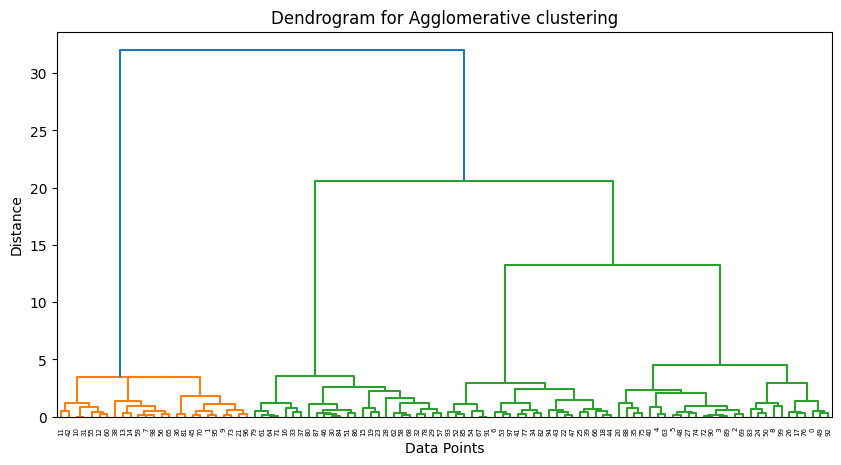

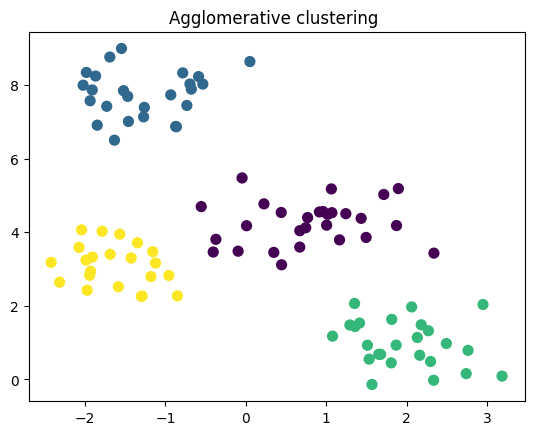

In [17]:
# Agglomerative clustering
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import make_blobs
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

# Creating the data as required
x,_=make_blobs(n_samples=100, centers=4, cluster_std=0.6, random_state=0)

# Creating the dendrogram
plt.figure(figsize=(10,5))
sch.dendrogram(sch.linkage(x,method='ward'))
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.title('Dendrogram for Agglomerative clustering')
plt.show()

# Applying Agglomerative clustering
agc = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
# n_clusters=4, means we want 4 clusters
# metric='euclidean', means we want to measure euclidean distance
# linkage='ward' is a method to minimize the variance between clusters

# Fit the model
labels=agc.fit_predict(x)

# Visualizing clusters
plt.scatter(x[:,0], x[:,1], c=labels, cmap='viridis',s=50)

# Adding the title
plt.title('Agglomerative clustering ')
plt.show()